# Étape 10.2 : long-short sur les facteurs de Fama et French

On n'achète plus des actions du S&P 500 : on investit directement dans les cinq facteurs de style de French (SMB, HML, RMW, CMA, Mom), chacun étant déjà un portefeuille long-short. L'étage 2 décide du poids de chaque facteur : équipondération ou ERC. On compare au long-only de l'étape 9.

## 1. Données et outils de l'étape 9

In [1]:
import io
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.optimize import minimize
from scipy.stats import norm
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "docs" / "figures"

pd.set_option("display.precision", 3)
pd.set_option("display.width", 140)

In [2]:
base = pd.read_csv(ROOT / "data" / "processed" / "zscores_sp500_mensuels.csv.gz")
base["mois"] = pd.PeriodIndex(base["mois"], freq="M")
base = base.set_index(["mois", "ticker"]).sort_index()

ajustes = pd.read_csv(RAW / "sp500_cours_ajustes_mensuels.csv", index_col=0)
ajustes.index = pd.PeriodIndex(ajustes.index.astype(str).str[:7], freq="M")
rendements = ajustes.pct_change(fill_method=None)


def lire_bloc_mensuel(chemin_zip):
    with zipfile.ZipFile(chemin_zip) as z:
        texte = z.read(z.namelist()[0]).decode("latin-1")
    lignes = texte.splitlines()
    debut = next(i for i, l in enumerate(lignes) if l.startswith(","))
    bloc = [lignes[debut]]
    for l in lignes[debut + 1:]:
        if not l.strip() or not l.strip()[0].isdigit():
            break
        bloc.append(l)
    df = pd.read_csv(io.StringIO("\n".join(bloc)), index_col=0)
    df.columns = df.columns.str.strip()
    df.index = pd.PeriodIndex(df.index.astype(str), freq="M")
    return df.astype(float) / 100


facteurs = lire_bloc_mensuel(RAW / "F-F_Research_Data_5_Factors_2x3_CSV.zip").join(
    lire_bloc_mensuel(RAW / "F-F_Momentum_Factor_CSV.zip"), how="inner")
rf = facteurs["RF"]

etf = pd.read_csv(RAW / "cours_mensuels.csv", index_col=0)[["SPY", "RSP"]]
etf.index = pd.PeriodIndex(etf.index, freq="M")
rend_etf = etf.pct_change()

mois = base.index.get_level_values("mois").unique()
print(f"z-scores : {mois[0]} à {mois[-1]}, {len(mois)} mois")

z-scores : 2012-02 à 2026-08, 175 mois


In [3]:
STYLES = {"z_smb": "SMB", "z_hml": "HML", "z_rmw": "RMW", "z_cma": "CMA", "z_mom": "Mom"}
Z = base[list(STYLES)]

In [4]:
def poids_erc(cov):
    # Spinu (2013) : le minimum de 1/2 y'Σy - (1/n) Σ log(y) donne des contributions au risque égales.
    n = len(cov)
    y0 = 1 / np.sqrt(np.diag(cov))
    y = minimize(lambda y: 0.5 * y @ cov @ y - np.log(y).sum() / n, y0,
                 jac=lambda y: cov @ y - 1 / (n * y), bounds=[(1e-10, None)] * n, method="L-BFGS-B").x
    return y / y.sum()


def contributions(w, cov):
    rc = w * (cov @ w)
    return rc / rc.sum()


poids = {}
for m in mois:
    histo = facteurs.loc[:m, list(STYLES.values())].iloc[-60:]
    poids[m] = poids_erc(histo.cov().values)
poids = pd.DataFrame(poids, index=list(STYLES.values())).T

# Contrôle : contributions au risque au dernier mois
cov_fin = facteurs.loc[:mois[-1], list(STYLES.values())].iloc[-60:].cov().values
print("Contributions au risque (dernier mois) :", np.round(contributions(poids.iloc[-1].values, cov_fin), 3))
print("\nPoids ERC des facteurs dans le score, résumé sur la période :")
poids.describe().loc[["mean", "min", "max"]].round(2)

Contributions au risque (dernier mois) : [0.2 0.2 0.2 0.2 0.2]

Poids ERC des facteurs dans le score, résumé sur la période :


,SMB,HML,RMW,CMA,Mom
mean,0.23,0.13,0.30,0.18,0.17
min,0.17,0.08,0.25,0.12,0.08
max,0.32,0.22,0.36,0.23,0.22


In [5]:
def score_final(w):
    # w : DataFrame (mois x facteurs) de poids
    wl = w.reindex(Z.index.get_level_values("mois")).set_axis(Z.index)
    wl.columns = list(STYLES)
    s = (Z.fillna(0) * wl).sum(axis=1)[Z.notna().sum(axis=1) >= 3]
    return s.groupby(level="mois").transform(lambda x: (x - x.mean()) / x.std())


egal = pd.DataFrame(0.2, index=mois, columns=list(STYLES.values()))
scores = pd.DataFrame({"score_equipondere": score_final(egal), "score_erc": score_final(poids)})

scores.to_csv(ROOT / "data" / "processed" / "scores_finaux_sp500.csv.gz", float_format="%.5g")

In [6]:
capi = base["capitalisation"]
PLAFOND = 0.10


def plafonner(w, plafond=PLAFOND):
    # Aucune action au-dessus du plafond ; l'excédent est redistribué aux autres, au prorata.
    w = w / w.sum()
    while (w > plafond + 1e-12).any():
        trop = w > plafond
        excedent = (w[trop] - plafond).sum()
        w[trop] = plafond
        w[~trop] += excedent * w[~trop] / w[~trop].sum()
    return w


def poids_cibles(score, seuil=0.30, tampon=0.40, ponderation="capi_score"):
    cibles, tenus = {}, set()
    for m in mois[:-1]:
        s = score.xs(m).dropna()
        c = capi.xs(m).reindex(s.index).dropna()
        s = s[c.index]
        rang = s.rank(ascending=False, pct=True)
        selection = set(rang[rang <= seuil].index)
        if tampon:
            selection |= set(rang[rang <= tampon].index) & tenus
        selection = sorted(selection)
        tenus = set(selection)
        if ponderation == "egale":
            w = pd.Series(1.0, index=selection)
        elif ponderation == "capi":
            w = c[selection]
        else:
            w = c[selection] * (1 + s[selection]).clip(lower=0)
        cibles[m] = plafonner(w)
    return cibles

In [7]:
def backtest(cibles, frais=0.0010):
    lignes, derive, manquants = {}, pd.Series(dtype=float), 0
    for m, w in cibles.items():
        rotation = w.subtract(derive, fill_value=0).abs().sum()
        r = rendements.loc[m + 1].reindex(w.index)
        manquants += int(r.isna().sum())
        r = r.fillna(0)
        brut = float((w * r).sum())
        lignes[m + 1] = {"brut": brut, "rotation": rotation, "net": brut - frais * rotation}
        derive = w * (1 + r)
        derive = derive / derive.sum()
    sortie = pd.DataFrame(lignes).T
    sortie.attrs["manquants"] = manquants
    return sortie


def univers_capi():
    return {m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]}

In [8]:
def test_moyenne(a):
    m = sm.OLS(a.values, np.ones(len(a))).fit(cov_type="HAC", cov_kwds={"maxlags": 6})
    return m.params[0], m.tvalues[0], m.pvalues[0]


def indices_bootstrap(n, bloc_moyen, rng):
    idx = np.empty(n, dtype=int)
    idx[0] = rng.integers(n)
    for i in range(1, n):
        idx[i] = rng.integers(n) if rng.random() < 1 / bloc_moyen else (idx[i - 1] + 1) % n
    return idx


def sharpe(x, r_f):
    e = x - r_f
    return e.mean() / e.std() * np.sqrt(12)


def bootstrap(strat, bench, n_tirages=5000, bloc_moyen=6, graine=0):
    rng = np.random.default_rng(graine)
    s, b, f = strat.values, bench.values, rf.reindex(strat.index).values
    actif, d_sharpe = [], []
    for _ in range(n_tirages):
        i = indices_bootstrap(len(s), bloc_moyen, rng)
        actif.append((s[i] - b[i]).mean() * 12)
        d_sharpe.append(sharpe(s[i], f[i]) - sharpe(b[i], f[i]))
    return np.percentile(actif, [2.5, 97.5]), np.percentile(d_sharpe, [2.5, 97.5])

## 2. Les frais d'un portefeuille long-short

Les facteurs de French sont calculés **sans frais**. Or chaque facteur se rééquilibre en permanence : le momentum, en particulier, change de composition tous les mois. On mesure donc la rotation de chaque jambe sur nos facteurs reconstruits (étape 8.4, mêmes règles : 30 % / 30 %, pondération par la capitalisation), et on applique les mêmes 0,10 % par dollar échangé qu'à l'étape 9.

C'est une estimation basse : French inclut des petites capitalisations, plus chères à échanger que celles du S&P 500. Le coût d'emprunt des titres vendus à découvert n'est pas compté.

In [9]:
def rotation_facteur(col):
    # Rotation mensuelle moyenne d'un facteur long-short : jambe achetée + jambe vendue.
    d = base[[col, "capitalisation"]].dropna()
    derive = {"haut": pd.Series(dtype=float), "bas": pd.Series(dtype=float)}
    rotations = []
    for m in mois[:-1]:
        g = d.xs(m)
        r = rendements.loc[m + 1].reindex(g.index)
        g, r = g[r.notna()], r[r.notna()]
        bas, haut = g[col].quantile([0.3, 0.7])
        total = 0.0
        for jambe, masque in [("haut", g[col] >= haut), ("bas", g[col] <= bas)]:
            w = g.loc[masque, "capitalisation"] / g.loc[masque, "capitalisation"].sum()
            if len(derive[jambe]):
                total += w.subtract(derive[jambe], fill_value=0).abs().sum()
            nouveau = w * (1 + r[w.index])
            derive[jambe] = nouveau / nouveau.sum()
        rotations.append(total)
    return np.mean(rotations[1:])


FRAIS = 0.0010
rotation = pd.Series({STYLES[c]: rotation_facteur(c) for c in STYLES})
cout_mensuel = FRAIS * rotation
pd.DataFrame({"rotation annuelle (deux jambes)": 12 * rotation, "coût annuel": 12 * cout_mensuel}).style.format(
    {"rotation annuelle (deux jambes)": "{:.0%}", "coût annuel": "{:.2%}"})

,rotation annuelle (deux jambes),coût annuel
SMB,197%,0.20%
HML,263%,0.26%
RMW,173%,0.17%
CMA,299%,0.30%
Mom,1178%,1.18%


## 3. Le backtest long-short

Chaque fin de mois $t$, poids $w_{k,t}$ des cinq facteurs (somme = 1) :
- **équipondéré** : 20 % chacun ;
- **ERC** : contributions au risque égales, covariance des 60 mois précédents (comme à l'étape 9).

Rendement du mois suivant, net de frais :

$$r_{t+1} = \sum_k w_{k,t}\,(F_{k,t+1} - c_k) - 2 \times 0{,}001 \times \sum_k |w_{k,t} - w^{\text{dérivé}}_{k,t}|$$

où $c_k$ est le coût mensuel interne du facteur $k$, et le dernier terme le coût de rééquilibrage entre facteurs (chaque facteur a deux jambes).

Un facteur long-short n'immobilise pas de capital : c'est déjà un rendement **en excès** du taux sans risque. Il se compare donc au **rendement actif** du long-only (stratégie − univers), qui est lui aussi un pari pur sur les facteurs.

In [10]:
NOMS = list(STYLES.values())


def backtest_long_short(w, debut, fin):
    w = w.loc[debut:fin]
    sortie, prec = {}, None
    for m in w.index:
        if m + 1 not in facteurs.index:
            continue
        f = facteurs.loc[m + 1, NOMS]
        cible = w.loc[m, NOMS]
        reequilibrage = 0.0 if prec is None else (cible - prec).abs().sum()
        brut = float((cible * f).sum())
        net = float((cible * (f - cout_mensuel)).sum()) - 2 * FRAIS * reequilibrage
        sortie[m + 1] = {"brut": brut, "net": net}
        derive = cible * (1 + f)
        prec = derive / derive.sum()
    return pd.DataFrame(sortie).T


# Poids ERC sur tout l'historique de French (60 mois de recul)
historique = facteurs[NOMS].dropna()
poids_ls = {}
for i in range(59, len(historique)):
    poids_ls[historique.index[i]] = poids_erc(historique.iloc[i - 59:i + 1].cov().values)
poids_ls = pd.DataFrame(poids_ls, index=NOMS).T
egal_ls = pd.DataFrame(0.2, index=poids_ls.index, columns=NOMS)
print(f"Historique long-short possible : {poids_ls.index[0] + 1} à {historique.index[-1]}")

Historique long-short possible : 1968-07 à 2026-08


In [11]:
def resume(r):
    m, t, _ = test_moyenne(r)
    valeur = (1 + r).cumprod()
    return pd.Series({"rendement annuel": 12 * r.mean(), "volatilité": r.std() * np.sqrt(12),
                      "Sharpe": r.mean() / r.std() * np.sqrt(12), "t (Newey-West)": t,
                      "perte maximale": (valeur / valeur.cummax() - 1).min()})


# Période commune avec l'étape 9
DEBUT, FIN = pd.Period("2012-02", "M"), pd.Period("2026-07", "M")
ls = {"Long-short équipondéré": backtest_long_short(egal_ls, DEBUT, FIN),
      "Long-short ERC": backtest_long_short(poids_ls, DEBUT, FIN)}
periode = ls["Long-short ERC"].index

lo = {"score équipondéré": backtest(poids_cibles(scores["score_equipondere"])),
      "score ERC": backtest(poids_cibles(scores["score_erc"]))}
univers = backtest({m: capi.xs(m).dropna() / capi.xs(m).dropna().sum() for m in mois[:-1]})

tableau = {}
for nom, bt in ls.items():
    tableau[(nom, "brut")] = resume(bt["brut"])
    tableau[(nom, "net de frais")] = resume(bt["net"])
for nom, bt in lo.items():
    tableau[(f"Long-only {nom} (actif)", "net de frais")] = resume((bt["net"] - univers["net"]).reindex(periode))
print(f"Période : {periode[0]} à {periode[-1]}, {len(periode)} mois")
pd.DataFrame(tableau).T.style.format({"rendement annuel": "{:+.2%}", "volatilité": "{:.1%}", "Sharpe": "{:+.2f}",
                                      "t (Newey-West)": "{:+.2f}", "perte maximale": "{:.1%}"})

Période : 2012-03 à 2026-08, 174 mois


In [12]:
# ERC contre équipondéré, en long-short
a = ls["Long-short ERC"]["net"] - ls["Long-short équipondéré"]["net"]
m, t, p = test_moyenne(a)
print(f"ERC - équipondéré (long-short, net) : {12 * m:+.2%} par an, t = {t:+.2f}, p = {p:.2f}")
print(f"Volatilité : ERC {ls['Long-short ERC']['net'].std() * np.sqrt(12):.1%}, "
      f"équipondéré {ls['Long-short équipondéré']['net'].std() * np.sqrt(12):.1%}")

ERC - équipondéré (long-short, net) : +0.00% par an, t = +0.01, p = 0.99
Volatilité : ERC 4.0%, équipondéré 4.6%


## 4. Sur tout l'historique de French

Même calcul de juillet 1968 (60 mois de recul nécessaires) à août 2026. Les frais internes sont ceux mesurés sur 2012-2026, appliqués à toute la période.

In [13]:
debut_h = poids_ls.index[0]
ls_h = {"Long-short équipondéré": backtest_long_short(egal_ls, debut_h, FIN),
        "Long-short ERC": backtest_long_short(poids_ls, debut_h, FIN)}
lignes = {}
for nom, bt in ls_h.items():
    for sp, (d, f) in {"1968-2011": ("1968-07", "2011-12"), "2012-2026": ("2012-03", "2026-08"),
                       "tout": ("1968-07", "2026-08")}.items():
        lignes[(nom, sp)] = resume(bt["net"].loc[d:f])
pd.DataFrame(lignes).T.style.format({"rendement annuel": "{:+.2%}", "volatilité": "{:.1%}", "Sharpe": "{:+.2f}",
                                     "t (Newey-West)": "{:+.2f}", "perte maximale": "{:.1%}"})

In [14]:
a = ls_h["Long-short ERC"]["net"] - ls_h["Long-short équipondéré"]["net"]
m, t, p = test_moyenne(a)
r_erc, r_eq = ls_h["Long-short ERC"]["net"], ls_h["Long-short équipondéré"]["net"]
print(f"1968-2026, ERC - équipondéré : {12 * m:+.2%} par an, t = {t:+.2f}")
print(f"Sharpe : ERC {r_erc.mean() / r_erc.std() * np.sqrt(12):.2f}, équipondéré {r_eq.mean() / r_eq.std() * np.sqrt(12):.2f}")
print(f"Volatilité : ERC {r_erc.std() * np.sqrt(12):.1%}, équipondéré {r_eq.std() * np.sqrt(12):.1%}")

1968-2026, ERC - équipondéré : -0.33% par an, t = -1.28
Sharpe : ERC 0.69, équipondéré 0.67
Volatilité : ERC 4.1%, équipondéré 4.7%


## 5. Graphique

In [15]:
SURFACE, TEXTE, TEXTE2, GRILLE = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLEU, ORANGE, AQUA, JAUNE, MAGENTA, VERT = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"
GRIS = "#8d8c88"

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXTE, "axes.labelcolor": TEXTE2, "xtick.color": TEXTE2, "ytick.color": TEXTE2,
    "axes.edgecolor": GRILLE, "axes.grid": True, "grid.color": GRILLE, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})


def sauver(fig, nom):
    fig.savefig(FIG / nom, dpi=200, bbox_inches="tight")


def virgule(fmt):
    return plt.FuncFormatter(lambda v, _: fmt.format(v).replace(".", ",").replace("-", "−"))


COULEURS = {"Score équipondéré": BLEU, "Score ERC": ORANGE, "Univers (capitalisation)": TEXTE2, "SPY": GRIS}

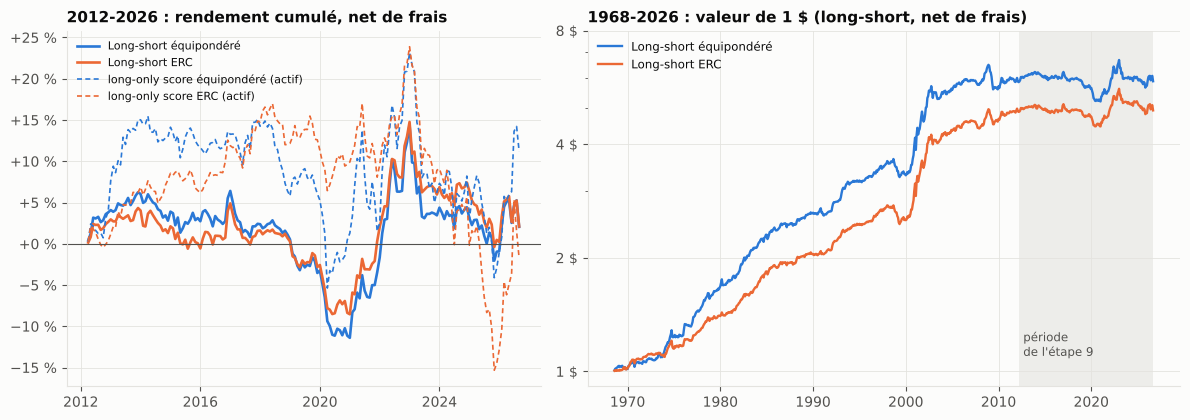

In [16]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={"width_ratios": [1, 1.25]})
d = periode.to_timestamp(how="end")
for nom, couleur, style in [("Long-short équipondéré", BLEU, "-"), ("Long-short ERC", ORANGE, "-")]:
    ax1.plot(d, 100 * ls[nom]["net"].cumsum(), color=couleur, lw=1.9, ls=style, label=nom)
for nom, couleur in [("score équipondéré", BLEU), ("score ERC", ORANGE)]:
    a = (lo[nom]["net"] - univers["net"]).reindex(periode)
    ax1.plot(d, 100 * a.cumsum(), color=couleur, lw=1.2, ls=(0, (3, 2)), label=f"long-only {nom} (actif)")
ax1.axhline(0, color=TEXTE2, lw=0.8)
ax1.yaxis.set_major_formatter(virgule("{:+.0f} %"))
ax1.xaxis.set_major_locator(mdates.YearLocator(4))
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax1.set_title("2012-2026 : rendement cumulé, net de frais")
ax1.legend(loc="upper left", fontsize=8)

dh = ls_h["Long-short ERC"].index.to_timestamp(how="end")
for nom, couleur in [("Long-short équipondéré", BLEU), ("Long-short ERC", ORANGE)]:
    ax2.plot(dh, (1 + ls_h[nom]["net"]).cumprod(), color=couleur, lw=1.7, label=nom)
ax2.set_yscale("log")
ax2.set_yticks([1, 2, 4, 8])
ax2.yaxis.set_major_formatter(virgule("{:.0f} $"))
ax2.yaxis.set_minor_formatter(plt.NullFormatter())
ax2.axvspan(pd.Timestamp("2012-03-01"), dh[-1], color=GRILLE, alpha=0.6, lw=0)
ax2.text(pd.Timestamp("2012-09-01"), 1.1, "période\nde l'étape 9", fontsize=8.5, color=TEXTE2)
ax2.set_title("1968-2026 : valeur de 1 $ (long-short, net de frais)")
ax2.legend(loc="upper left", fontsize=8.5)
fig.tight_layout()
sauver(fig, "long_short_facteurs.png")
plt.show()